<a href="https://colab.research.google.com/github/OlenaBogoliubova/DATA-LOVE-ACADEMY/blob/main/HW_%D0%92%D1%81%D1%82%D1%83%D0%BF_%D0%B4%D0%BE_%D0%BD%D0%B5%D0%B9%D1%80%D0%BE%D0%BD%D0%BD%D0%B8%D1%85_%D0%BC%D0%B5%D1%80%D0%B5%D0%B6_Bogoliubova.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Секція 1. Логістична регресія з нуля.**

Будемо крок за кроком будувати модель лог регресії з нуля для передбачення, чи буде врожай більше за 80 яблук (задача подібна до лекційної, але на класифікацію).

Давайте нагадаємо основні формули для логістичної регресії.

### Функція гіпотези - обчислення передбачення у логістичній регресії:

$$
\hat{y} = \sigma(x W^T + b) = \frac{1}{1 + e^{-(x W^T + b)}}
$$

Де:
- $ \hat{y} $ — це ймовірність "позитивного" класу.
- $ x $ — це вектор (або матриця для набору прикладів) вхідних даних.
- $ W $ — це вектор (або матриця) вагових коефіцієнтів моделі.
- $ b $ — це зміщення (bias).
- $ \sigma(z) $ — це сигмоїдна функція активації.

### Як обчислюється сигмоїдна функція:

Сигмоїдна функція $ \sigma(z) $ має вигляд:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

Ця функція перетворює будь-яке дійсне значення $ z $ в інтервал від 0 до 1, що дозволяє інтерпретувати вихід як ймовірність для логістичної регресії.

### Формула функції втрат для логістичної регресії (бінарна крос-ентропія):

Функція втрат крос-ентропії оцінює, наскільки добре модель передбачає класи, порівнюючи передбачені ймовірності $ \hat{y} $ із справжніми мітками $ y $. Формула наступна:

$$
L(y, \hat{y}) = - \left[ y \cdot \log(\hat{y}) + (1 - y) \cdot \log(1 - \hat{y}) \right]
$$

Де:
- $ y $ — це справжнє значення (мітка класу, 0 або 1).
- $ \hat{y} $ — це передбачене значення (ймовірність).



1.
Тут вже наведений код для ініціювання набору даних в форматі numpy. Перетворіть `inputs`, `targets` на `torch` тензори. Виведіть результат на екран.

In [16]:
import torch
import numpy as np

In [17]:
# Вхідні дані (temp, rainfall, humidity)
inputs = np.array([[73, 67, 43],
                   [91, 88, 64],
                   [87, 134, 58],
                   [102, 43, 37],
                   [69, 96, 70]], dtype='float32')

# Таргети (apples > 80)
targets = np.array([[0],
                    [1],
                    [1],
                    [0],
                    [1]], dtype='float32')

In [18]:
# Перетворюємо numpy масиви на torch тензори
inputs = torch.from_numpy(inputs)
targets = torch.from_numpy(targets)

# Виводимо результат
print(inputs)
print(targets)

tensor([[ 73.,  67.,  43.],
        [ 91.,  88.,  64.],
        [ 87., 134.,  58.],
        [102.,  43.,  37.],
        [ 69.,  96.,  70.]])
tensor([[0.],
        [1.],
        [1.],
        [0.],
        [1.]])


2. Ініціюйте ваги `w`, `b` для моделі логістичної регресії потрібної форми зважаючи на розмірності даних випадковими значеннями з нормального розподілу. Лишаю тут код для фіксації `random_seed`.

In [19]:
torch.random.manual_seed(1)

In [37]:
# 3 вхідні ознаки -> 1 вихід
w = torch.randn(1, 3, requires_grad=True)
b = torch.randn(1, requires_grad=True)

print(w)
print(b)

tensor([[-0.1955, -0.9656,  0.4224]], requires_grad=True)
tensor([0.2673], requires_grad=True)


3. Напишіть функцію `model`, яка буде обчислювати функцію гіпотези в логістичній регресії і дозволяти робити передбачення на основі введеного рядка даних і коефіцієнтів в змінних `w`, `b`.

  **Важливий момент**, що функція `model` робить обчислення на `torch.tensors`, тож для математичних обчислень використовуємо фукнціонал `torch`, наприклад:
  - обчсилення $e^x$: `torch.exp(x)`
  - обчсилення $log(x)$: `torch.log(x)`
  - обчислення середнього значення вектору `x`: `torch.mean(x)`

  Використайте функцію `model` для обчислення передбачень з поточними значеннями `w`, `b`.Виведіть результат обчислень на екран.

  Проаналізуйте передбачення. Чи не викликають вони у вас підозр? І якщо викликають, то чим це може бути зумовлено?

In [48]:
def model(x):
    z = x @ w.t() + b
    return 1 / (1 + torch.exp(-z))

preds = model(inputs)
print(preds)

tensor([[5.1098e-27],
        [1.6818e-33],
        [0.0000e+00],
        [1.6227e-20],
        [6.9108e-34]], grad_fn=<MulBackward0>)


Великі значення ознак. Температура, опади й вологість — це числа від десятків до сотень (наприклад, 73, 134). Множення на випадкові ваги порядку 0.1-1 дає z у десятки або сотні.
Насичення сигмоїди. При великих за модулем z сигмоїда дуже близька до 1 (для великих додатних) або до 0 (для великих від'ємних). Тому всі передбачення однакові й «впевнені», хоч модель ще нічого не навчилась.
Наслідок для навчання. У насичених зонах градієнт сигмоїди майже нульовий, тому навчання буде дуже повільним або зовсім не піде.

4. Напишіть функцію `binary_cross_entropy`, яка приймає на вхід передбачення моделі `predicted_probs` та справжні мітки в даних `true_labels` і обчислює значення втрат (loss)  за формулою бінарної крос-ентропії для кожного екземпляра та вертає середні втрати по всьому набору даних.
  Використайте функцію `binary_cross_entropy` для обчислення втрат для поточних передбачень моделі.

In [49]:
def binary_cross_entropy(predicted_probs, true_labels):
    # Втрати для кожного екземпляра
    losses = -(true_labels * torch.log(predicted_probs) +
               (1 - true_labels) * torch.log(1 - predicted_probs))
    # Середнє значення по всьому набору даних
    return torch.mean(losses)

loss = binary_cross_entropy(preds, targets)
print(loss)

tensor(inf, grad_fn=<MeanBackward0>)


5. Зробіть зворотнє поширення помилки і виведіть градієнти за параметрами `w`, `b`. Проаналізуйте їх значення. Як гадаєте, чому вони саме такі?

In [50]:
loss.backward()

print(w.grad)
print(b.grad)

tensor([[nan, nan, nan]])
tensor([nan])


Коли ми ініціювали значення випадковими значеннями з нормального розподілу, насправді ці значення не були дуже гарними стартовими значеннями і привели до того, що градієнти стали дуже малими або навіть рівними нулю (це призводить до того, що градієнти "зникають"), і відповідно при оновленні ваг у нас не буде нічого змінюватись. Це називається `gradient vanishing`. Це відбувається через насичення сигмоїдної функції активації.

Саме це сталося в задачі, де великі випадкові значення ваг викликали насичення сигмоїдної функції. Це в свою чергу призводить до того, що під час зворотного поширення помилки (backpropagation) модель оновлює ваги дуже повільно або зовсім не оновлює.

5. Виконайте код та знову обчисліть передбачення, лосс і знайдіть градієнти та виведіть всі ці тензори на екран.

In [73]:
torch.random.manual_seed(1)
w = torch.randn(1, 3, requires_grad=True)  # Листовий тензор
b = torch.randn(1, requires_grad=True)     # Листовий тензор

# in-place операції
w.data = w.data / 1000
b.data = b.data / 1000

In [74]:
# model з урахуванням нової форми w (1, 3)
def model(x):
    z = x @ w.t() + b
    return 1 / (1 + torch.exp(-z))

# Передбачення
preds = model(inputs)
print(preds)

# Лосс
loss = binary_cross_entropy(preds, targets)
print(loss)

# Градієнти
loss.backward()
print(w.grad)
print(b.grad)

tensor([[0.5174],
        [0.5220],
        [0.5244],
        [0.5204],
        [0.5190],
        [0.5174],
        [0.5220],
        [0.5244],
        [0.5204],
        [0.5190],
        [0.5174],
        [0.5220],
        [0.5244],
        [0.5204],
        [0.5190]], grad_fn=<MulBackward0>)
tensor(0.6829, grad_fn=<MeanBackward0>)
tensor([[ -5.4417, -18.9853, -10.0682]])
tensor([-0.0794])


6. Напишіть алгоритм градієнтного спуску, який буде навчати модель з використанням написаних раніше функцій і виконуючи оновлення ваг. Алгоритм має включати наступні кроки:

  1. Генерація прогнозів
  2. Обчислення втрат
  3. Обчислення градієнтів (gradients) loss-фукнції відносно ваг і зсувів
  4. Налаштування ваг шляхом віднімання невеликої величини, пропорційної градієнту (`learning_rate` домножений на градієнт)
  5. Скидання градієнтів на нуль

Виконайте градієнтний спуск протягом 1000 епох, обчисліть фінальні передбачення і проаналізуйте, чи вони точні?

In [75]:
learning_rate = 1e-5
epochs = 1000

# Градієнти із завдання 5 ще лежать у w.grad і b.grad, тому спочатку скидаємо їх
w.grad.zero_()
b.grad.zero_()

for epoch in range(epochs):
    # 7. Генерація прогнозів
    preds = model(inputs)

    # 8. Обчислення втрат
    loss = binary_cross_entropy(preds, targets)

    # 9. Обчислення градієнтів
    loss.backward()

    # 10. Оновлення ваг (без відстеження градієнтів)
    with torch.no_grad():
        w -= learning_rate * w.grad
        b -= learning_rate * b.grad

    # 11. Скидання градієнтів на нуль
    w.grad.zero_()
    b.grad.zero_()

    # Виводимо loss кожні 100 епох, щоб бачити прогрес
    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch + 1}, loss: {loss.item():.4f}")

# Фінальні передбачення
preds = model(inputs)
print(preds)
print(targets)

# Перетворюємо ймовірності на класи (поріг 0.5) для порівняння з targets
print((preds > 0.5).float())

Epoch 100, loss: 0.5632
Epoch 200, loss: 0.5075
Epoch 300, loss: 0.4654
Epoch 400, loss: 0.4330
Epoch 500, loss: 0.4076
Epoch 600, loss: 0.3873
Epoch 700, loss: 0.3708
Epoch 800, loss: 0.3571
Epoch 900, loss: 0.3456
Epoch 1000, loss: 0.3359
tensor([[0.5777],
        [0.6685],
        [0.9113],
        [0.1618],
        [0.8653],
        [0.5777],
        [0.6685],
        [0.9113],
        [0.1618],
        [0.8653],
        [0.5777],
        [0.6685],
        [0.9113],
        [0.1618],
        [0.8653]], grad_fn=<MulBackward0>)
tensor([[0.],
        [1.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [1.],
        [0.],
        [1.]])
tensor([[1.],
        [1.],
        [1.],
        [0.],
        [1.],
        [1.],
        [1.],
        [1.],
        [0.],
        [1.],
        [1.],
        [1.],
        [1.],
        [0.],
        [1.]])


Висновок про точність:

Правильно класифіковано 4 з 5 рядків, тобто точність 80%.
Помилився перший рядок: справжня мітка 0, а модель дає 0.58. Це невпевнене передбачення, лише трохи вище порогу 0.5.
Для рядків 3, 4, 5 модель уже досить впевнена (0.91, 0.16, 0.87), а для рядка 2 (0.67) впевненість помірна.


Loss ще падає, модель не дійшла до мінімуму. Причина в дуже малому learning rate (1e-5), який взяли, щоб уникнути nan. Більше епох або більший learning rate дали б кращий результат.

Дуже мало даних. П'ять рядків для навчання, і ми оцінюємо точність на тих самих даних, що й навчали. Це лише перевірка того, що алгоритм працює, а не показник якості на нових даних.

Отже, алгоритм градієнтного спуску працює правильно: модель навчається, і більшість передбачень збігаються з мітками, але вона ще недонавчена.

**Секція 2. Створення лог регресії з використанням функціоналу `torch.nn`.**

Давайте повторно реалізуємо ту ж модель, використовуючи деякі вбудовані функції та класи з PyTorch.

Даних у нас буде побільше - тож, визначаємо нові масиви.

In [76]:
# Вхідні дані (temp, rainfall, humidity)
inputs = np.array([[73, 67, 43],
                   [91, 88, 64],
                   [87, 134, 58],
                   [102, 43, 37],
                   [69, 96, 70],
                   [73, 67, 43],
                   [91, 88, 64],
                   [87, 134, 58],
                   [102, 43, 37],
                   [69, 96, 70],
                   [73, 67, 43],
                   [91, 88, 64],
                   [87, 134, 58],
                   [102, 43, 37],
                   [69, 96, 70]], dtype='float32')

# Таргети (apples > 80)
targets = np.array([[0],
                    [1],
                    [1],
                    [0],
                    [1],
                    [0],
                    [1],
                    [1],
                    [0],
                    [1],
                    [0],
                    [1],
                    [1],
                    [0],
                    [1]], dtype='float32')

7. Завантажте вхідні дані та мітки в PyTorch тензори та з них створіть датасет, який поєднує вхідні дані з мітками, використовуючи клас `TensorDataset`. Виведіть перші 3 елементи в датасеті.



In [77]:
from torch.utils.data import TensorDataset

# Перетворюємо numpy масиви на torch тензори
inputs = torch.from_numpy(inputs)
targets = torch.from_numpy(targets)

# Створюємо датасет, який поєднує вхідні дані з мітками
train_ds = TensorDataset(inputs, targets)

# Виводимо перші 3 елементи
print(train_ds[:3])

(tensor([[ 73.,  67.,  43.],
        [ 91.,  88.,  64.],
        [ 87., 134.,  58.]]), tensor([[0.],
        [1.],
        [1.]]))


8. Визначте data loader з класом **DataLoader** для підготовленого датасету `train_ds`, встановіть розмір батчу на 5 та увімкніть перемішування даних для ефективного навчання моделі. Виведіть перший елемент в дата лоадері.

In [78]:
from torch.utils.data import DataLoader

batch_size = 5
train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True)

# Перший елемент (батч) у даталоадері
print(next(iter(train_dl)))

[tensor([[ 73.,  67.,  43.],
        [ 91.,  88.,  64.],
        [102.,  43.,  37.],
        [ 69.,  96.,  70.],
        [102.,  43.,  37.]]), tensor([[0.],
        [1.],
        [0.],
        [1.],
        [0.]])]


9. Створіть клас `LogReg` для логістичної регресії, наслідуючи модуль `torch.nn.Module` за прикладом в лекції (в частині про FeedForward мережі).

  У нас модель складається з лінійної комбінації вхідних значень і застосування фукнції сигмоїда. Тож, нейромережа буде складатись з лінійного шару `nn.Linear` і використання активації `nn.Sigmid`. У створеному класі мають бути реалізовані методи `__init__` з ініціалізацією шарів і метод `forward` для виконання прямого проходу моделі через лінійний шар і функцію активації.

  Створіть екземпляр класу `LogReg` в змінній `model`.

In [79]:
import torch.nn as nn

class LogReg(nn.Module):
    def __init__(self):
        super().__init__()
        # Лінійний шар: 3 входи -> 1 вихід
        self.linear = nn.Linear(3, 1)
        # Активація: сигмоїда
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        out = self.linear(x)
        out = self.sigmoid(out)
        return out

model = LogReg()
print(model)

LogReg(
  (linear): Linear(in_features=3, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)


In [80]:
print(list(model.parameters()))

[Parameter containing:
tensor([[ 0.2109, -0.2250, -0.0421]], requires_grad=True), Parameter containing:
tensor([-0.0520], requires_grad=True)]


10. Задайте оптимізатор `Stockastic Gradient Descent` в змінній `opt` для навчання моделі логістичної регресії. А також визначіть в змінній `loss` функцію втрат `binary_cross_entropy` з модуля `torch.nn.functional` для обчислення втрат моделі. Обчисліть втрати для поточних передбачень і міток, а потім виведіть їх. Зробіть висновок, чи моделі вдалось навчитись?

In [81]:
import torch.nn.functional as F

# Оптимізатор SGD для параметрів моделі
opt = torch.optim.SGD(model.parameters(), lr=1e-5)

# Функція втрат
loss_fn = F.binary_cross_entropy

# Поточні передбачення і втрати
preds = model(inputs)
loss = loss_fn(preds, targets)
print(loss)

tensor(7.6312, grad_fn=<BinaryCrossEntropyBackward0>)


Моделі ще не вдалось навчитись. Втрата 7.63 значно гірша за 0.69, яку дала б модель, що завжди відповідає «50/50». Тобто поточні передбачення гірші за випадкове вгадування.

11. Візьміть з лекції функцію для тренування моделі з відстеженням значень втрат і навчіть щойно визначену модель на 1000 епохах. Виведіть після цього графік зміни loss, фінальні передбачення і значення таргетів.

In [82]:
# Модифікована функцію fit для відстеження втрат
def fit_return_loss(num_epochs, model, loss_fn, opt, train_dl):
    losses = []
    for epoch in range(num_epochs):
        # Ініціалізуємо акумулятор для втрат
        total_loss = 0

        for xb, yb in train_dl:
            # Генеруємо передбачення
            pred = model(xb)

            # Обчислюємо втрати
            loss = loss_fn(pred, yb)

            # Виконуємо градієнтний спуск
            loss.backward()
            opt.step()
            opt.zero_grad()

            # Накопичуємо втрати
            total_loss += loss.item()

        # Обчислюємо середні втрати для епохи
        avg_loss = total_loss / len(train_dl)
        losses.append(avg_loss)

        # Виводимо підсумок епохи
        if (epoch + 1) % 10 == 0:
          print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}')
    return losses

In [85]:
# Train the model for 1000 epochs
loss = fit_return_loss(1000, model, loss_fn, opt, train_dl)

Epoch [10/1000], Loss: 2.0062
Epoch [20/1000], Loss: 1.9342
Epoch [30/1000], Loss: 1.8632
Epoch [40/1000], Loss: 1.7922
Epoch [50/1000], Loss: 1.7232
Epoch [60/1000], Loss: 1.6485
Epoch [70/1000], Loss: 1.5853
Epoch [80/1000], Loss: 1.5150
Epoch [90/1000], Loss: 1.4520
Epoch [100/1000], Loss: 1.3831
Epoch [110/1000], Loss: 1.3171
Epoch [120/1000], Loss: 1.2595
Epoch [130/1000], Loss: 1.2084
Epoch [140/1000], Loss: 1.1388
Epoch [150/1000], Loss: 1.0851
Epoch [160/1000], Loss: 1.0415
Epoch [170/1000], Loss: 0.9843
Epoch [180/1000], Loss: 0.9393
Epoch [190/1000], Loss: 0.8865
Epoch [200/1000], Loss: 0.8436
Epoch [210/1000], Loss: 0.8030
Epoch [220/1000], Loss: 0.7632
Epoch [230/1000], Loss: 0.7308
Epoch [240/1000], Loss: 0.7033
Epoch [250/1000], Loss: 0.6679
Epoch [260/1000], Loss: 0.6437
Epoch [270/1000], Loss: 0.6134
Epoch [280/1000], Loss: 0.5918
Epoch [290/1000], Loss: 0.5703
Epoch [300/1000], Loss: 0.5492
Epoch [310/1000], Loss: 0.5325
Epoch [320/1000], Loss: 0.5149
Epoch [330/1000],

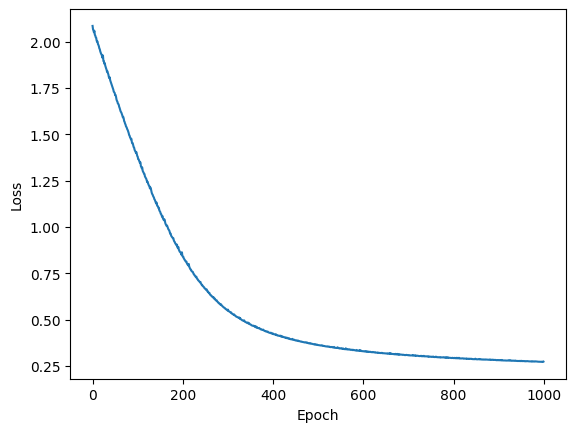

In [86]:
import matplotlib.pyplot as plt
plt.plot(loss)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

Модель навчається успішно: loss зменшився приблизно у 8 разів і став набагато меншим за 0.69 (рівень «50/50»). Це означає, що вона вже розрізняє рядки з y = 0 та y = 1. Плато показує, що подальше збільшення кількості епох дасть лише невелике покращення.